<a href="https://colab.research.google.com/github/dilp90/Introduccion_a_Aprendizaje_Maquina/blob/main/CNN_Pneumonia_IaAM.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Ejercicio de Red Neuronal Convolucional**

Link en Kaggle para el dataset: https://www.kaggle.com/datasets/paultimothymooney/chest-xray-pneumonia

In [2]:
#Librerías

import os
import cv2
import matplotlib.pyplot as plt

In [1]:
# 1. Inyectamos el nuevo token de la interfaz que me mostraste
os.environ['KAGGLE_API_TOKEN'] = "KGAT_5bb99cf8489d4a3f6b84daf4752d27bc"

# 2. Nos aseguramos de tener la herramienta oficial de Kaggle en Python instalada
!pip install kaggle -q

# 3. Descargamos usando el comando correcto de Python (¡Sin npx!)
!kaggle datasets download -d paultimothymooney/chest-xray-pneumonia

# 4. Descomprimimos el archivo ZIP resultante
print("Descomprimiendo imágenes médicas...")
!unzip -q chest-xray-pneumonia.zip
print("¡Descarga completada con éxito!")

Dataset URL: https://www.kaggle.com/datasets/paultimothymooney/chest-xray-pneumonia
License(s): other
100% 2.29G/2.29G [00:21<00:00, 113MB/s] 

Descomprimiendo imágenes médicas...
¡Descarga completada con éxito!


Mostrando: person1673_bacteria_4434.jpeg
Resolución Original: 896 x 624 píxeles



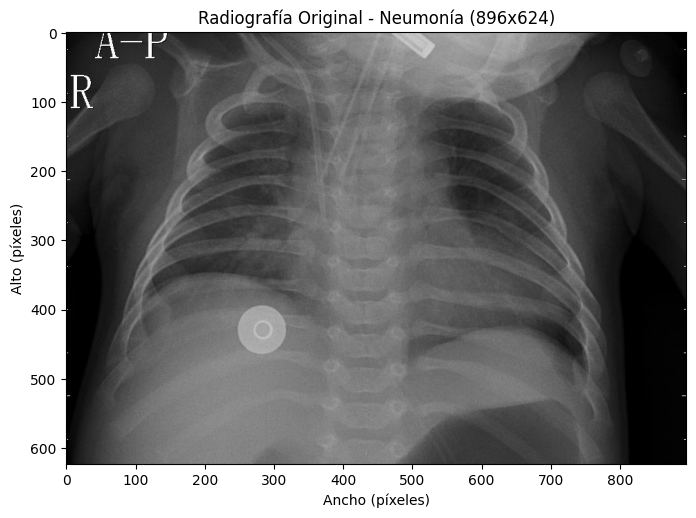

In [3]:
# 1. Definimos la ruta de la carpeta de radiografías de neumonía
carpeta_neumonia = './chest_xray/train/PNEUMONIA'

# 2. Obtenemos la lista con los nombres de todos los archivos de imagen
imagenes = [f for f in os.listdir(carpeta_neumonia) if f.lower().endswith(('.jpeg', '.jpg', '.png'))]

# 3. Elegimos una imagen (por ejemplo, la primera de la lista) y la cargamos completa
nombre_archivo = imagenes[1]
ruta_completa = os.path.join(carpeta_neumonia, nombre_archivo)

# cv2.IMREAD_GRAYSCALE asegura que se lea en su escala de grises original
img_original = cv2.imread(ruta_completa)

# 4. Visualización con su resolución nativa en los ejes
alto, ancho, otro = img_original.shape
print(f"Mostrando: {nombre_archivo}")
print(f"Resolución Original: {ancho} x {alto} píxeles\n")

plt.figure(figsize=(8, 8))
plt.imshow(img_original, cmap='gray')
plt.title(f"Radiografía Original - Neumonía ({ancho}x{alto})")
plt.xlabel("Ancho (píxeles)")
plt.ylabel("Alto (píxeles)")
plt.grid(False)
plt.show()

Resolución Original: 896 x 624
Nueva Resolución Estándar: 150 x 150



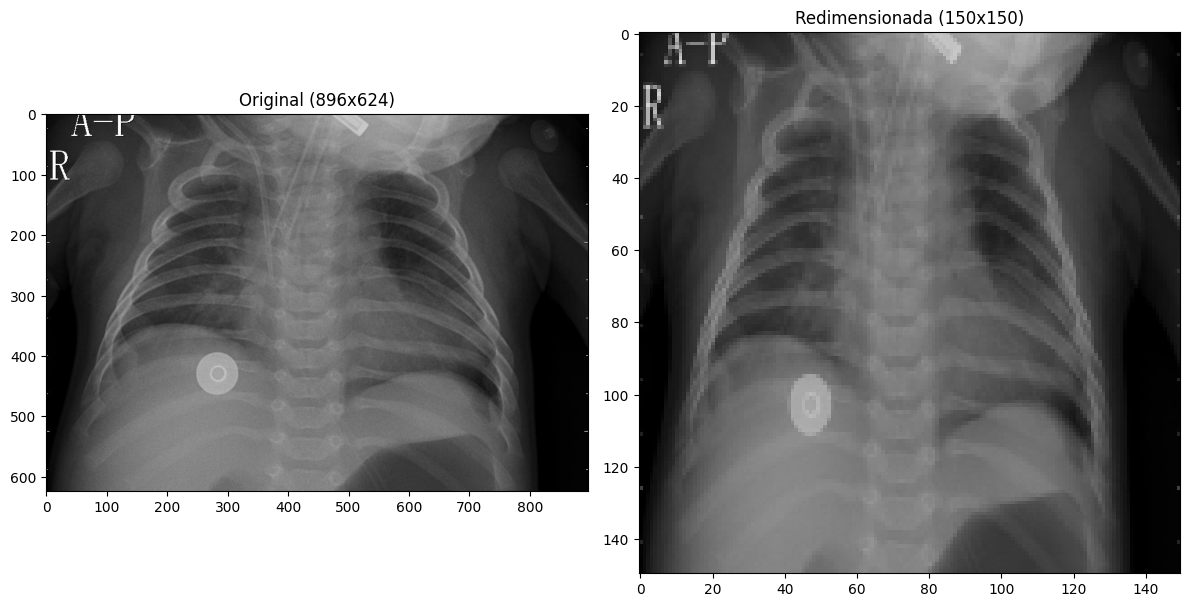

In [4]:
# Definimos la resolución estándar que queremos para todas nuestras imágenes
RESOLUCION_ESTANDAR = (150, 150) # (ancho, alto)

# Redimensionamos la imagen original usando cv2.resize
img_redimensionada = cv2.resize(img_original, RESOLUCION_ESTANDAR, interpolation=cv2.INTER_AREA)

# Mostramos los detalles y comparamos las resoluciones
alto_redim, ancho_redim, canales_redim = img_redimensionada.shape
print(f"Resolución Original: {ancho} x {alto}")
print(f"Nueva Resolución Estándar: {ancho_redim} x {alto_redim}\n")

# Visualizamos ambas imágenes lado a lado
fig, axes = plt.subplots(1, 2, figsize=(12, 6))

# Imagen original
axes[0].imshow(cv2.cvtColor(img_original, cv2.COLOR_BGR2RGB))
axes[0].set_title(f"Original ({ancho}x{alto})")
axes[0].axis('on')

# Imagen redimensionada
axes[1].imshow(cv2.cvtColor(img_redimensionada, cv2.COLOR_BGR2RGB))
axes[1].set_title(f"Redimensionada ({ancho_redim}x{alto_redim})")
axes[1].axis('on')

plt.tight_layout()
plt.show()